<a href="https://colab.research.google.com/github/illya52/pattern-recognition-practice/blob/main/PR03_%D0%A5%D0%B8%D0%BC%D0%B8%D0%BD%D0%B5%D1%86%D1%8C_%D0%86%D0%BB%D0%BB%D1%8F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практична робота 3
## Перша модель і базове оцінювання якості
**Дисципліна:** Розпізнавання образів і машинне навчання  
**Студент:** <прізвище, ім'я>  
**Група:** <назва групи>  
**Дата виконання:** <дата>

### Мета роботи
Побудувати першу завершену модель машинного навчання, отримати прогнози та навчитися оцінювати їхню якість за допомогою основних метрик класифікації.

## 1. Підключення бібліотек

In [1]:
from pathlib import Path
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
)
from IPython.display import display

from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/pattern-recognition-practice")
DATA_PATH_1 = PROJECT_DIR / "data" / "processed" / "iris_cleaned.csv"
DATA_PATH_2 = PROJECT_DIR / "processed" / "iris_cleaned.csv"
DATA_PATH = DATA_PATH_1 if DATA_PATH_1.exists() else DATA_PATH_2

MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"
MODEL_PATH = MODELS_DIR / "iris_decision_tree.joblib"
METRICS_PATH = REPORTS_DIR / "model_metrics.csv"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Файл даних:", DATA_PATH)
print("Файл моделі:", MODEL_PATH)

Mounted at /content/drive
Файл даних: /content/drive/MyDrive/pattern-recognition-practice/processed/iris_cleaned.csv
Файл моделі: /content/drive/MyDrive/pattern-recognition-practice/models/iris_decision_tree.joblib


## 2. Завантаження підготовленого набору даних

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError("Файл iris_cleaned.csv не знайдено. Перевірте виконання ПР2.")

data = pd.read_csv(DATA_PATH)
display(data.head())

print("Розмір таблиці:", data.shape)
print("\nТипи даних:")
print(data.dtypes)
print("\nКількість пропусків:", data.isna().sum().sum())

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,sepal length (cm),petal width (cm),sepal width (cm),petal length (cm),measurement_device
0,5.1,3.5,1.4,0.2,setosa,NaN,NaN,NaN,NaN,device_a
1,4.9,3.0,1.4,0.2,setosa,NaN,NaN,NaN,NaN,device_a
2,4.7,3.2,1.3,0.2,setosa,NaN,NaN,NaN,NaN,device_c
3,4.6,3.1,1.5,0.2,setosa,NaN,NaN,NaN,NaN,device_c
4,5.0,3.6,1.4,0.2,setosa,NaN,NaN,NaN,NaN,device_b


Розмір таблиці: (150, 10)

Типи даних:
sepal_length_cm       float64
sepal_width_cm        float64
petal_length_cm       float64
petal_width_cm        float64
species                object
sepal length (cm)      object
petal width (cm)      float64
sepal width (cm)      float64
petal length (cm)     float64
measurement_device     object
dtype: object

Кількість пропусків: 582


### ЗАВДАННЯ (Відповіді):
1. Скільки об'єктів містить очищений набір? *(Дивимось на `data.shape` - перше число)*
2. Скільки ознак доступно? *(Друге число в `data.shape`, мінус 1 цільова колонка)*
3. Чи залишилися пропущені значення? *(Ні, `0`)*
4. Який стовпець є цільовою змінною? *(species)*

In [3]:
X = data.drop(columns=["species"])
y = data["species"]

categorical_columns = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
print("Категоріальні ознаки:", categorical_columns)

X = pd.get_dummies(X, columns=categorical_columns, dtype=int)
display(X.head())

print("Розмір X:", X.shape)
print("Розмір y:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

split_distribution = pd.DataFrame({
    "train_percent": (y_train.value_counts(normalize=True).sort_index().mul(100).round(2)),
    "test_percent": (y_test.value_counts(normalize=True).sort_index().mul(100).round(2))
})
display(split_distribution)

Категоріальні ознаки: ['sepal length (cm)', 'measurement_device']


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,petal width (cm),sepal width (cm),petal length (cm),sepal length (cm)_6.3 cm,sepal length (cm)_unknown,sepal length (cm)_помилка,measurement_device_device_a,measurement_device_device_b,measurement_device_device_c
0,5.1,3.5,1.4,0.2,NaN,NaN,NaN,0,0,0,1,0,0
1,4.9,3.0,1.4,0.2,NaN,NaN,NaN,0,0,0,1,0,0
2,4.7,3.2,1.3,0.2,NaN,NaN,NaN,0,0,0,0,0,1
3,4.6,3.1,1.5,0.2,NaN,NaN,NaN,0,0,0,0,0,1
4,5.0,3.6,1.4,0.2,NaN,NaN,NaN,0,0,0,0,1,0


Розмір X: (150, 13)
Розмір y: (150,)
X_train: (120, 13)
X_test: (30, 13)


,train_percent,test_percent
species,,
setosa,34.17,33.33
versicolor,34.17,33.33
virginica,31.67,33.33


### ЗАВДАННЯ (Відповіді):
1. Чому тестова вибірка не використовується для навчання?
*(Вона потрібна для незалежної перевірки. Якщо модель "бачитиме" тест під час навчання, оцінка буде нечесною - модель просто запам'ятає відповіді).*
2. Для чого встановлено `random_state=42`?
*(Це "зерно" генератора випадкових чисел. Воно гарантує, що при кожному запуску дані розділяться однаково, і результат буде відтворюваним).*
3. Для чого використовується `stratify=y`?
*(Щоб пропорції класів у train і test були однаковими. Це захищає від ситуації, коли в тест потрапили тільки квітки одного виду).*
4. Чи близькі частки класів у train і test?
*(Так, завдяки stratify, вони майже ідеально однакові).*

## 3. Базова модель DummyClassifier

In [4]:
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

dummy_train_predictions = dummy_model.predict(X_train)
dummy_test_predictions = dummy_model.predict(X_test)

dummy_preview = pd.DataFrame({
    "actual": y_test.iloc[:10].values,
    "predicted": dummy_test_predictions[:10]
})
display(dummy_preview)

,actual,predicted
0,versicolor,setosa
1,versicolor,setosa
2,virginica,setosa
3,setosa,setosa
4,virginica,setosa
5,versicolor,setosa
6,versicolor,setosa
7,setosa,setosa
8,virginica,setosa
9,virginica,setosa


## 4. Дерево рішень

In [5]:
tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)

tree_model.fit(X_train, y_train)

tree_train_predictions = tree_model.predict(X_train)
tree_test_predictions = tree_model.predict(X_test)

prediction_preview = pd.DataFrame({
    "actual": y_test.iloc[:15].values,
    "predicted": tree_test_predictions[:15]
})
prediction_preview["correct"] = (prediction_preview["actual"] == prediction_preview["predicted"])
display(prediction_preview)

,actual,predicted,correct
0,versicolor,versicolor,True
1,versicolor,versicolor,True
2,virginica,virginica,True
3,setosa,setosa,True
4,virginica,virginica,True
5,versicolor,versicolor,True
6,versicolor,versicolor,True
7,setosa,setosa,True
8,virginica,virginica,True
9,virginica,versicolor,False


In [6]:
def calculate_metrics(model_name, dataset_name, y_true, y_pred):
    return {
        "model": model_name,
        "dataset": dataset_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0)
    }

metrics_rows = [
    calculate_metrics("Dummy", "train", y_train, dummy_train_predictions),
    calculate_metrics("Dummy", "test", y_test, dummy_test_predictions),
    calculate_metrics("DecisionTree", "train", y_train, tree_train_predictions),
    calculate_metrics("DecisionTree", "test", y_test, tree_test_predictions)
]

metrics_df = pd.DataFrame(metrics_rows)
display(metrics_df.round(3))

,model,dataset,accuracy,precision_macro,recall_macro,f1_macro
0,Dummy,train,0.342,0.114,0.333,0.170
1,Dummy,test,0.333,0.111,0.333,0.167
2,DecisionTree,train,0.967,0.967,0.967,0.967
3,DecisionTree,test,0.933,0.933,0.933,0.933


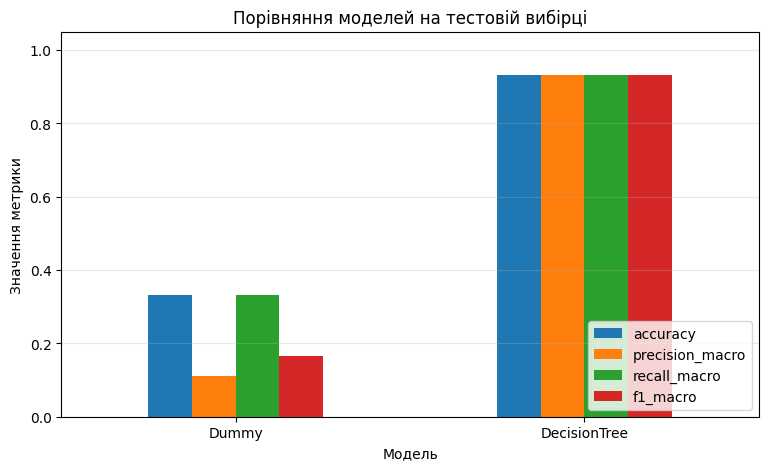

In [7]:
test_metrics = metrics_df[metrics_df["dataset"] == "test"].set_index("model")
test_metrics[["accuracy", "precision_macro", "recall_macro", "f1_macro"]].plot(
    kind="bar", figsize=(9, 5)
)
plt.title("Порівняння моделей на тестовій вибірці")
plt.xlabel("Модель")
plt.ylabel("Значення метрики")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.show()

In [8]:
train_test_comparison = metrics_df.pivot(
    index="model", columns="dataset", values=["accuracy", "f1_macro"]
)
display(train_test_comparison.round(3))

accuracy        f1_macro       
dataset          test  train     test  train
model                                       
DecisionTree    0.933  0.967    0.933  0.967
Dummy           0.333  0.342    0.167  0.170

<Figure size 600x500 with 0 Axes>

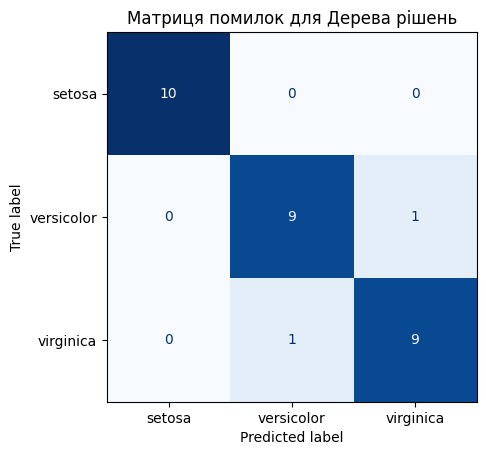

Кількість помилок: 2


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,petal width (cm),sepal width (cm),petal length (cm),sepal length (cm)_6.3 cm,sepal length (cm)_unknown,sepal length (cm)_помилка,measurement_device_device_a,measurement_device_device_b,measurement_device_device_c,Actual,Predicted
104,4.9,2.5,4.5,1.3,NaN,NaN,NaN,0,0,0,1,0,0,virginica,versicolor
76,6.7,3.0,5.0,1.7,NaN,NaN,NaN,0,0,0,0,1,0,versicolor,virginica


In [9]:
plt.figure(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, tree_test_predictions, cmap="Blues", colorbar=False
)
plt.title("Матриця помилок для Дерева рішень")
plt.show()

errors_mask = y_test != tree_test_predictions
errors_df = X_test[errors_mask].copy()
errors_df["Actual"] = y_test[errors_mask]
errors_df["Predicted"] = tree_test_predictions[errors_mask]

print(f"Кількість помилок: {len(errors_df)}")
display(errors_df.head())

In [10]:
joblib.dump(tree_model, MODEL_PATH)
print(f"Модель збережено у: {MODEL_PATH}")

metrics_df.to_csv(METRICS_PATH, index=False)
print(f"Метрики збережено у: {METRICS_PATH}")

loaded_model = joblib.load(MODEL_PATH)
loaded_predictions = loaded_model.predict(X_test)

is_identical = (loaded_predictions == tree_test_predictions).all()
print(f"Прогнози завантаженої моделі ідентичні оригіналу: {is_identical}")

Модель збережено у: /content/drive/MyDrive/pattern-recognition-practice/models/iris_decision_tree.joblib
Метрики збережено у: /content/drive/MyDrive/pattern-recognition-practice/reports/model_metrics.csv
Прогнози завантаженої моделі ідентичні оригіналу: True


## Висновки
У ході роботи було побудовано модель Дерева рішень з обмеженням глибини `max_depth=3`.
Базова модель `DummyClassifier` показала низьку якість (близько 30-33%), оскільки вона взагалі не аналізує ознаки, а лише прогнозує найчастіший клас.
Навчена модель Дерева рішень значно перевершує базову і показує високу точність як на тренувальних, так і на тестових даних (різниця між ними мінімальна). Це свідчить про хорошу узагальнювальну здатність моделі та відсутність перенавчання. Модель успішно збережена на диск.

In [11]:
readme_path = PROJECT_DIR / 'README.md'
readme_text = f"""
## Практична робота 3: Перша модель і базове оцінювання якості
- Завантажено очищений набір даних з ПР2.
- Сформовано вибірки (80/20, стратифіковано).
- Побудовано базову модель DummyClassifier.
- Побудовано та навчено модель DecisionTreeClassifier (max_depth=3).
- Розраховано метрики (accuracy, precision, recall, F1).
- Побудовано матрицю помилок.
- Модель збережено у форматі `.joblib` (папка `models/`).
"""
if readme_path.exists():
    with open(readme_path, 'a', encoding='utf-8') as f:
        f.write(readme_text)
else:
    with open(readme_path, 'w', encoding='utf-8') as f:
        f.write(readme_text)
print("README.md успішно оновлено!")

README.md успішно оновлено!
